<a href="https://colab.research.google.com/github/lvs42/lvs42.github.io/blob/main/PELICULAS_Practica_modulo2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Introducción**

En este caso teórico-práctico se va a analizar el dataset [Movie Dataset for Analytics & Visualization](https://www.kaggle.com/datasets/mjshubham21/movie-dataset-for-analytics-and-visualization).

En esta práctica se pretende analizar un dataset sobre las películas estrenadas entre los años 1995 y 2025 para intentar encontrar datos interesantes que no se pueden observar a simple vista.

In [ ]:
import os
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
from collections import defaultdict
import operator
import seaborn as sns
import numpy as np
from sklearn.linear_model import LinearRegression

# Análisis de datos

Para comenzar, es interesante tener una previsualización del csv en forma de tabla

In [ ]:
# url = "https://bucketsergiomendi.s3.us-east-1.amazonaws.com/industry.csv"
# Hemos utilizado un S3 para obtener el CSV, no obstante se utiliza kaggle para su descarga
path = kagglehub.dataset_download("mjshubham21/movie-dataset-for-analytics-and-visualization");

# Ver qué archivos hay dentro
files = os.listdir(path);

# Cargar el CSV correcto
moviesCSV = pd.read_csv(os.path.join(path, files[0]));

# Mostramos los datos
moviesCSV.head()

100%|██████████| 62.1M/62.1M [00:00<00:00, 161MB/s]

Extracting files...


,MovieID,Title,Genre,ReleaseYear,ReleaseDate,Country,BudgetUSD,US_BoxOfficeUSD,Global_BoxOfficeUSD,Opening_Day_SalesUSD,One_Week_SalesUSD,IMDbRating,RottenTomatoesScore,NumVotesIMDb,NumVotesRT,Director,LeadActor
0,1,Might toward capital,Comedy,2003,28-09-2003,China,6577427.79,6613685.82,15472035.66,1778530.85,3034053.32,6.2,58,7865,10596,Kristina Moore,Brian Mccormick
1,2,He however experience,Comedy,1988,14-02-1988,USA,1883810.10,1930949.15,3637731.12,247115.74,831828.84,5.2,44,1708,220,Benjamin Hudson,Ashley Pena
2,3,Star responsibility politics,Comedy,1971,02-11-1971,USA,2468079.29,4186694.69,7165111.24,878453.95,2171405.93,5.5,55,4678,7805,Kayla Young,Alexander Haley
3,4,Exactly live,Comedy,1998,06-08-1998,USA,1447311.46,2023683.92,4373820.26,570657.72,898886.01,7.3,87,2467,1751,Michael Ross,Patrick Barnett
4,5,Focus improve especially,Documentary,2021,17-12-2021,India,900915.86,2129629.10,3113017.38,361189.37,861775.91,6.1,67,5555,697,Faith Franklin,Duane Fletcher DDS


1. Obtenemos las dimensiones del dataset

In [ ]:
# Obtenemos lista de géneros
movies_genre_keys = list(moviesCSV['Genre'].unique());

# Obtener dimensiones del conjunto de datos
moviesCSV.shape


(999999, 17)

2. Verificar validez de los datos

In [ ]:
print("Total de nulos:", moviesCSV.isnull().sum().sum())
print("Duplicados:", moviesCSV.duplicated().sum())

Total de nulos: 0
Duplicados: 0


2. Analizamos el dataset bigdata dividiéndolo mediante el uso de chunks (debido al tamaño de la memoria) más pequeños

In [ ]:
# Inicializamos diccionario a 0
movies_genre_dict = {}
for i in movies_genre_keys: movies_genre_dict[i] = 0
movies_genre_dict
print(movies_genre_dict)

# Inicializamos una variable para calcular la media de bytes por chunk
ave_bytes = 0

# Inicializamos el contador de chunks
count = 0

for index, chunk in enumerate(pd.read_csv(os.path.join(path, files[0]), chunksize= 100000),start=1):
    # Guardamos la media de memoria por chunk
    ave_bytes += chunk.memory_usage().sum()

    for i in movies_genre_keys:
        count = len(chunk[chunk['Genre'] == i])
        movies_genre_dict[i] += count

print("Total number of chunks:",index)
ave_bytes = ave_bytes / index
print("Average bytes per loop:",ave_bytes)
print(movies_genre_dict)

{'Comedy': 0, 'Documentary': 0, 'Drama': 0, 'Horror': 0, 'Action': 0, 'Thriller': 0, 'Romance': 0, 'Sci-Fi': 0}
Total number of chunks: 10
Average bytes per loop: 13600118.4
{'Comedy': 199832, 'Documentary': 50114, 'Drama': 250018, 'Horror': 100010, 'Action': 150131, 'Thriller': 100071, 'Romance': 100021, 'Sci-Fi': 49802}


3. Visualizamos gráficamente el número de películas por género

{'Comedy': [199832], 'Documentary': [50114], 'Drama': [250018], 'Horror': [100010], 'Action': [150131], 'Thriller': [100071], 'Romance': [100021], 'Sci-Fi': [49802]}


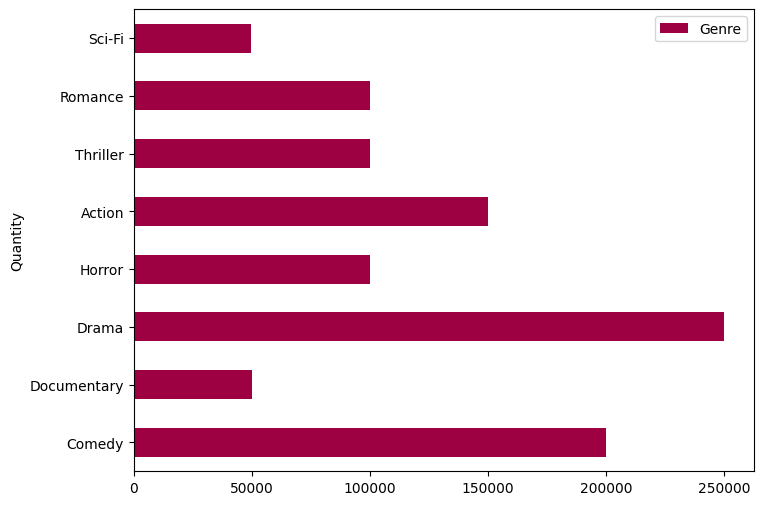

In [ ]:

# Vamos a visualizarlo gráficamente
empty_list = []
for i,j in movies_genre_dict.items():
    empty_list.append(j)
    movies_genre_dict[i] = empty_list
    empty_list = []
print(movies_genre_dict)

ratings_dict_df = pd.DataFrame(movies_genre_dict).T  # Let's tranpose it from row to column vector
ratings_dict_df = ratings_dict_df.reset_index()  # Let's reset the index from the rating keys back to default
ratings_dict_df.columns=['Quantity','Genre']
ratings_dict_df

ratings_dict_df.plot(kind='barh', x = 'Quantity' , y = 'Genre', figsize = (8,6), colormap = 'Spectral')

plt.show()

Visualizamos gráficamente el ingreso medio de películas por género

4. Debido a que tenemos un dataset balanceado, no nos es necesario emplear la libreria SMOTE, la cual aumentaria el número de registros de las clases con menores frecuencas con el objetivo de obtener un número equilibrado entre las clases.

5. Debido a que los datos son sufientemente grandes, no es necesario usar data augmentation el cual aumentaría los datos de forma sintética a partir de los datos existentes.

# Explicación de los datos de forma visual, explicabilidad IA

1. ¿Existe correlación entre el presupuesto y los ingresos de una película?

Correlación entre presupuesto e ingresos: 0.90


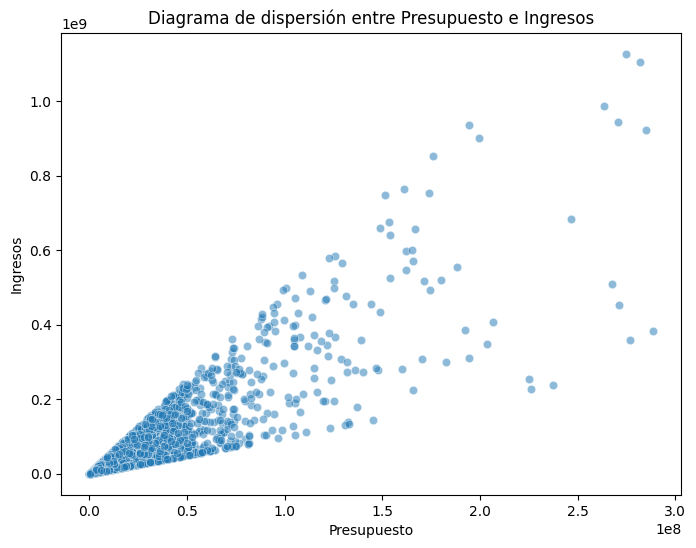

In [ ]:
#Obtenemos la correlación entre el presupuesto y los beneficios que genera una película
correlation = moviesCSV['BudgetUSD'].corr(moviesCSV['Global_BoxOfficeUSD'])
print(f"Correlación entre presupuesto e ingresos: {correlation:.2f}")

# Filtramos las películas según su presupuesto
df_filtered = moviesCSV[(moviesCSV['BudgetUSD'] >= 1000) & (moviesCSV['BudgetUSD'] < 290000000)]

# Tomamos una muestra de 10000 películas
movies_sample_10000 = df_filtered.sample(n=10000, random_state=42)  # random_state para reproducibilidad

#Visualización de los datos
plt.figure(figsize=(8,6))
sns.scatterplot(x='BudgetUSD', y='Global_BoxOfficeUSD', data=movies_sample_10000, alpha=0.5)

plt.title("Diagrama de dispersión entre Presupuesto e Ingresos")
plt.xlabel("Presupuesto")
plt.ylabel("Ingresos")
plt.show()

1. Conclusiones: Podemos obeservar una correlación clara entre el presupeusto de una pelicula y los ingresos obtenidos por dicha misma.
  * Películas con bajo presupuesto casi nunca alcanzan ingresos altísimos, esto se observa en la concentración de puntos en la parte inferior izquierda del gráfico.
  * Películas con alto presupuesto pueden dar tanto éxitos enormes como fracasos estrepitosos por lo tanto los puntos se dispersan más.

2. ¿Influye el presupuesto en la puntuación del público o de la crítica?

Correlación entre presupuesto y la puntuación IMBD: 0.00
Nota media de IMDb: 6.49
pPresupuesto medio: 9802823.55


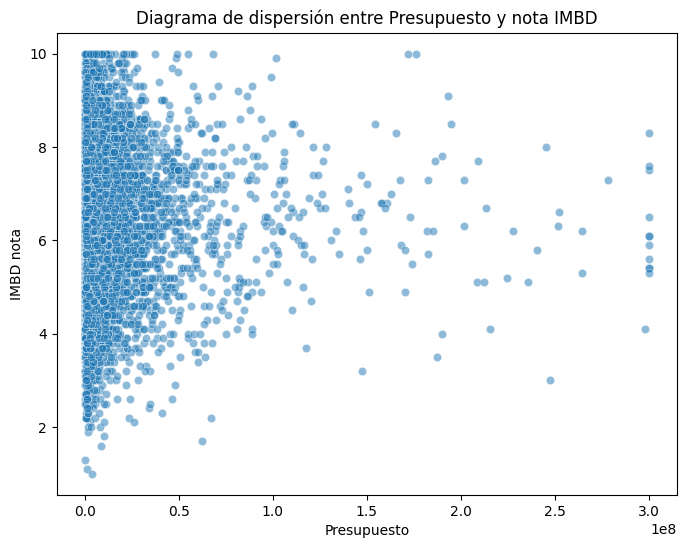

In [ ]:
#Obtenemos la correlación entre el presupuesto y la puntuación IMBD de la película
correlation2 = moviesCSV['BudgetUSD'].corr(moviesCSV['IMDbRating'])
print(f"Correlación entre presupuesto y la puntuación IMDb: {correlation2:.2f}")

mean_score = moviesCSV['IMDbRating'].mean()
print(f"Nota media de IMDb: {mean_score:.2f}")

mean_budget = moviesCSV['BudgetUSD'].mean()
print(f"pPresupuesto medio: {mean_budget:.2f}")

# Filtramos las películas según su presupuesto
#df_filtered_ = moviesCSV[(moviesCSV['BudgetUSD'] >= 1000) & (moviesCSV['BudgetUSD'] < 290000000)]

# Tomamos una muestra de 10000 películas
movies_sample_corr = moviesCSV.sample(n=10000, random_state=42)  # random_state para reproducibilidad

#Visualización de los datos
plt.figure(figsize=(8,6))
sns.scatterplot(x='BudgetUSD', y='IMDbRating', data=movies_sample_corr, alpha=0.5)

plt.title("Diagrama de dispersión entre Presupuesto y nota IMDb")
plt.xlabel("Presupuesto")
plt.ylabel("IMDb nota")
plt.show()

2. Conclusiones: no hay evidencia de que gastar más dinero en una película garantice una mejor nota de IMDb.

  * Una película puede tener millones de dólares y ser mediocre. Como le pasó a Waterworld (1995) que con un presupeusto de 170 millones de dolares apenas alcanza la nota de 6.3 en IMDb

  * Otra película de bajo presupuesto puede ser un éxito crítico, como es el caso de "El Padrino" (1972) que con tan solo 6 millones de presupuesto obtiene la segunda mejor nota en IMDb (9.2)

3. ¿Las películas con mayor popularidad son también las que tienen mayores ingresos?

Correlación entre la popularidad de una pelicula y los ingresos que genera: 0.00


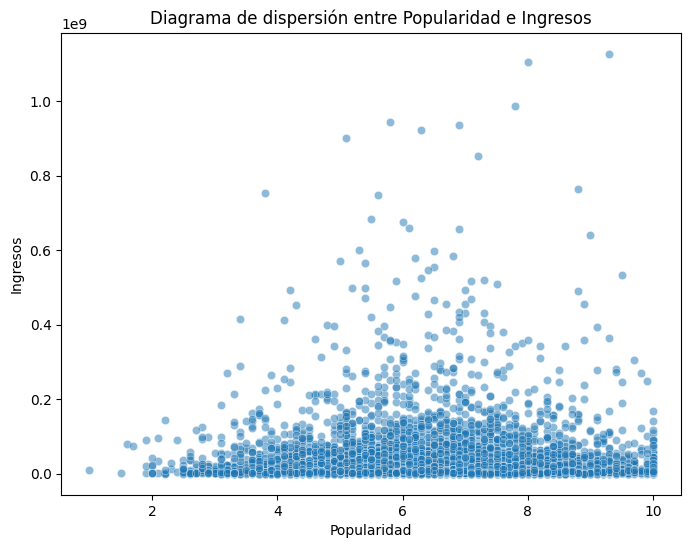

Correlación tras transformación logarítmica (IMDb vs log(Ingresos)): -0.00


In [ ]:
#Obtenemos la correlación entre la popularidad de una pelicula y los ingresos que genera
correlation = moviesCSV['IMDbRating'].corr(moviesCSV['Global_BoxOfficeUSD'])
print(f"Correlación entre la popularidad de una pelicula y los ingresos que genera: {correlation:.2f}")

# Filtramos las películas según su presupuesto
df_filtered = moviesCSV[(moviesCSV['BudgetUSD'] >= 1000) & (moviesCSV['BudgetUSD'] < 290000000)]

# Tomamos una muestra de 10000 películas
movies_sample_10000 = df_filtered.sample(n=10000, random_state=42)  # random_state para reproducibilidad

#Visualización de los datos
plt.figure(figsize=(8,6))
sns.scatterplot(x='IMDbRating', y='Global_BoxOfficeUSD', data=movies_sample_10000, alpha=0.5)

plt.title("Diagrama de dispersión entre Popularidad e Ingresos")
plt.xlabel("Popularidad")
plt.ylabel("Ingresos")
plt.show()

#Comprobación más extensa
df_valid = moviesCSV[['IMDbRating', 'Global_BoxOfficeUSD']].dropna()
df_valid = df_valid[df_valid['Global_BoxOfficeUSD'] > 0]  # evitar log(0)

corr_log = df_valid['IMDbRating'].corr(np.log1p(df_valid['Global_BoxOfficeUSD']))
print(f"Correlación tras transformación logarítmica (IMDb vs log(Ingresos)): {corr_log:.2f}")

3. Conclusiones: no hay evidencia de que gastar más dinero en una película garantice una mejor nota de IMDb. El rendimiento comercial no siempre va de la mano con la opinión del público o crítica


*   Existen películas muy taquilleras pero con malas críticas, por ejemplo, 'Fast & Furius X' (2023) (con 725 millones de dolares recaudados a nivel global y tan solo un 5,7 de nora en IMDb)
*   Hay películas excelentes para la  crítica pero poco vistas, como por ejemplo, 'El Club de la Lucha' (1999) con una increíble nota de 8,8 y tan solo 101 millones de dolares recaudados (cifra considerada baja al tener un presupuesto de  63 millones)



4. ¿Qué género genera mayores ingresos en promedio?

Genre
Documentary    2.758178e+07
Horror         2.748073e+07
Thriller       2.743435e+07
Romance        2.728314e+07
Comedy         2.721993e+07
Drama          2.715240e+07
Sci-Fi         2.697233e+07
Action         2.684386e+07
Name: Global_BoxOfficeUSD, dtype: float64


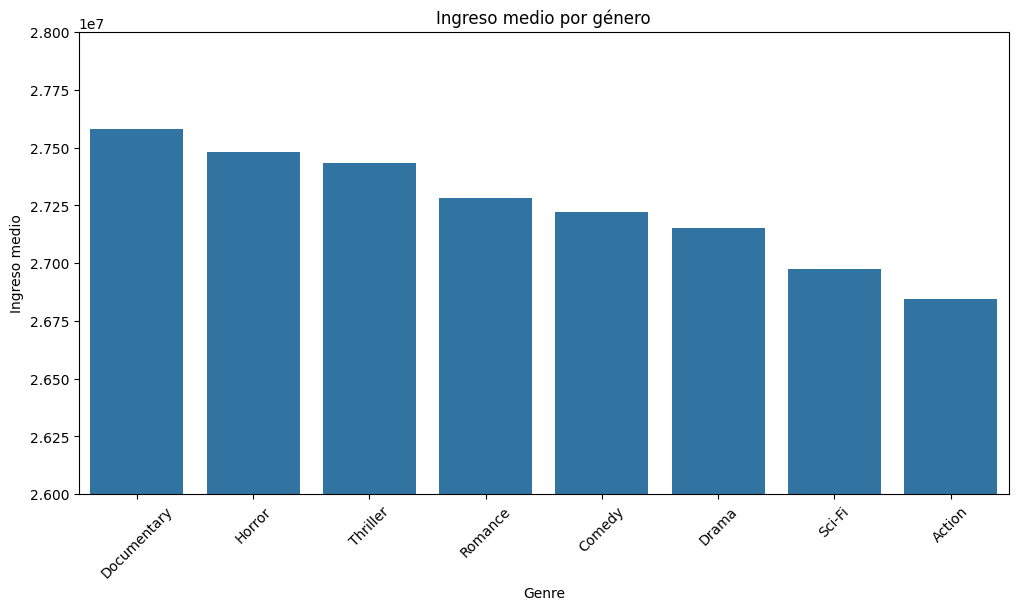

Genre
Thriller       8131587.980
Documentary    8130887.225
Drama          8109909.100
Romance        8094792.940
Horror         8093574.410
Comedy         8072080.510
Action         8051826.090
Sci-Fi         8014217.725
Name: Global_BoxOfficeUSD, dtype: float64


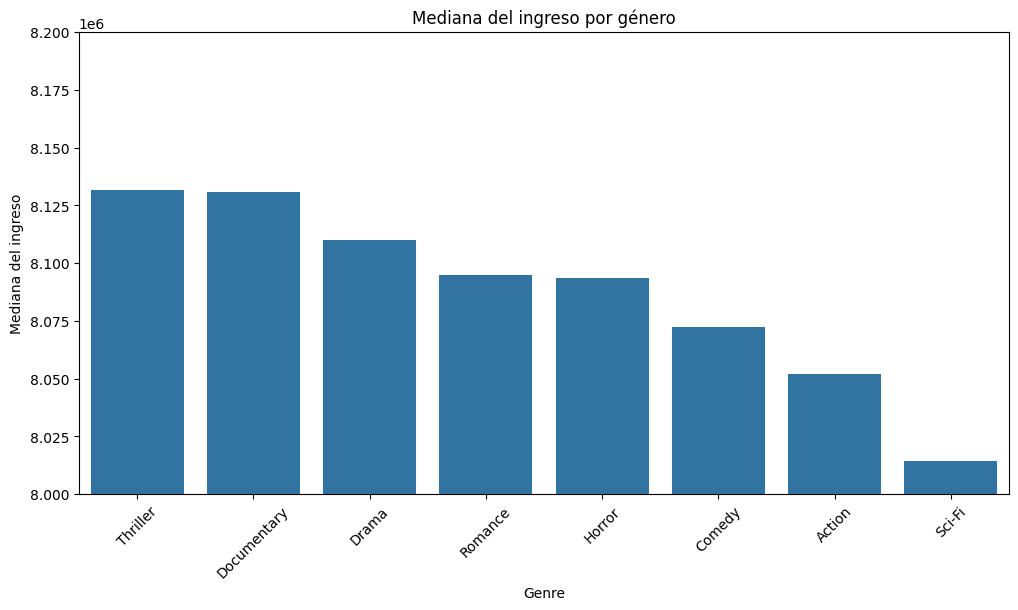

In [ ]:
mean_box_by_genre = moviesCSV.groupby('Genre')['Global_BoxOfficeUSD'].mean().sort_values(ascending=False)
print(mean_box_by_genre)

plt.figure(figsize=(12,6))
sns.barplot(x=mean_box_by_genre.index, y=mean_box_by_genre.values)
plt.xticks(rotation=45)
plt.ylabel("Ingreso medio")
plt.title("Ingreso medio por género")

plt.ylim(26_000_000, 28_000_000)

plt.show()

median_box_by_genre = moviesCSV.groupby('Genre')['Global_BoxOfficeUSD'].median().sort_values(ascending=False)
print(median_box_by_genre)

plt.figure(figsize=(12,6))
sns.barplot(x=median_box_by_genre.index, y=median_box_by_genre.values)
plt.xticks(rotation=45)
plt.ylabel("Mediana del ingreso")
plt.title("Mediana del ingreso por género")

plt.ylim(8000000, 8200000)

plt.show()

4. Conlusiones: Dado que la media puede verse alterada por valores extremos, se realizó una segunda comprobación utilizando la mediana. Al compararlas, se observa que, aunque hay ligeras diferencias entre géneros, no hay ninguno que destaque de forma significativa sobre los demás.

# MAPA DE CALOR

Ahora, vamos a comprobar de forma visual qué variables tienen correlación con otras, esto podemos lograrlo usando los mapas de calor entre las diferentes columnas del conjunto de datos. Los resultados muestran que la mayoría de las variables presentan una relación débil o inexistente entre sí, tal y como se ha comprobado en los análisis anteriores. Únicamente se observan correlaciones destacables entre el presupuesto y los ingresos, así como entre las valoraciones de IMDb y Rotten Tomatoes.

/tmp/ipython-input-161792872.py:4: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  moviesCSV['ReleaseDate'] = pd.to_datetime(moviesCSV['ReleaseDate'], errors='coerce')


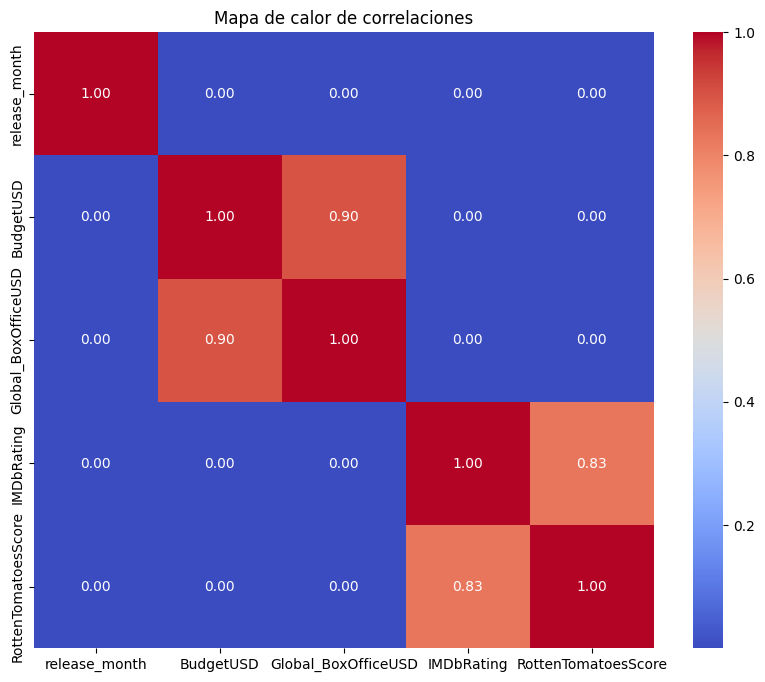

In [ ]:
# Mapa de calor de correlacioens numéricas

# Convertir la columna a tipo datetime
moviesCSV['ReleaseDate'] = pd.to_datetime(moviesCSV['ReleaseDate'], errors='coerce')

# Ahora ya puedes extraer el mes
moviesCSV['release_month'] = moviesCSV['ReleaseDate'].dt.month
numeric_cols = ['release_month', 'BudgetUSD', 'Global_BoxOfficeUSD', 'IMDbRating', 'RottenTomatoesScore']
corr_matrix = moviesCSV[numeric_cols].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Mapa de calor de correlaciones")
plt.show()

**Mapa de calor: presupeusto vs recaudación**

El siguiente mapa de calor representa la relación entre los rangos de presupuesto y recaudación global. Podemos observar que:

*   Las películas con presupuestos más altos tienden a obtener mayores ingresos, lo cual coincide con la correlación positiva encontrada anteriormente entre ambas variables.

* La mayoría de los títulos se concentran en los rangos intermedios de presupuesto e ingresos, lo que sugiere que la mayor parte de las producciones se sitúan en este nivel de inversión.



/tmp/ipython-input-920034823.py:10: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heatmap_data = moviesCSV.pivot_table(index='budget_bin', columns='revenue_bin', values='Title', aggfunc='count', fill_value=0)


<Axes: xlabel='revenue_bin', ylabel='budget_bin'>

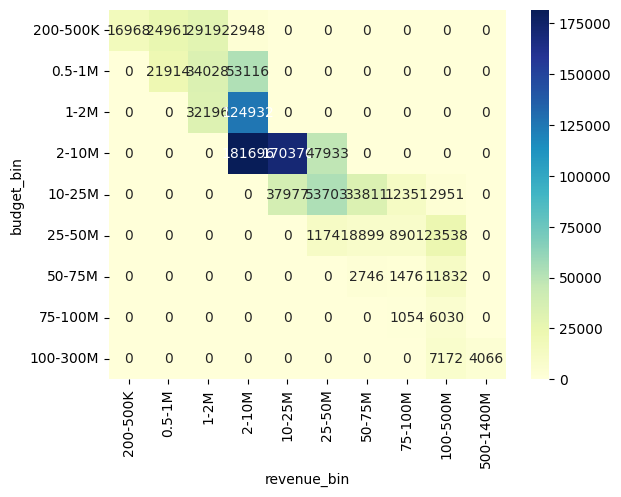

In [ ]:
bins_budget = [200_000, 500_000, 1_000_000, 2_000_000, 10_000_000, 25_000_000, 50_000_000, 75_000_000, 100_000_000, 300_000_000]
bins_revenue = [200_000, 500_000, 1_000_000, 2_000_000, 10_000_000, 25_000_000, 50_000_000, 75_000_000, 100_000_000, 500_000_000, 1_400_000_000]

labels_bin = ["200-500K", "0.5-1M", "1-2M", "2-10M", "10-25M", "25-50M", "50-75M", "75-100M", "100-300M"]
labels_revenue = ["200-500K", "0.5-1M", "1-2M", "2-10M", "10-25M", "25-50M", "50-75M", "75-100M", "100-500M", "500-1400M"]

moviesCSV['budget_bin'] = pd.cut(moviesCSV['BudgetUSD'], bins=bins_budget, labels=labels_bin )
moviesCSV['revenue_bin'] = pd.cut(moviesCSV['Global_BoxOfficeUSD'], bins=bins_revenue, labels=labels_revenue)

heatmap_data = moviesCSV.pivot_table(index='budget_bin', columns='revenue_bin', values='Title', aggfunc='count', fill_value=0)
sns.heatmap(heatmap_data, annot=True, fmt="d", cmap='YlGnBu')

**Mapa de calor: Ingresos por mes de estreno**

El mapa de calor a continuación muestra la recaudación de películas según el mes de estreno. Se observa que los mayores ingresos se concentran en julio y diciembre, con un segundo pico en septiembre, lo que refleja la importancia de la temporada de verano y las fiestas navideñas para la taquilla. Esta inforamción parece muy interesante peusto que conocer los meses en los que se genera mayor taquilla es útil para tomar decisiones estratégicas de marketing, planificar el estreno de una película y maximizar su rendimiento económico.

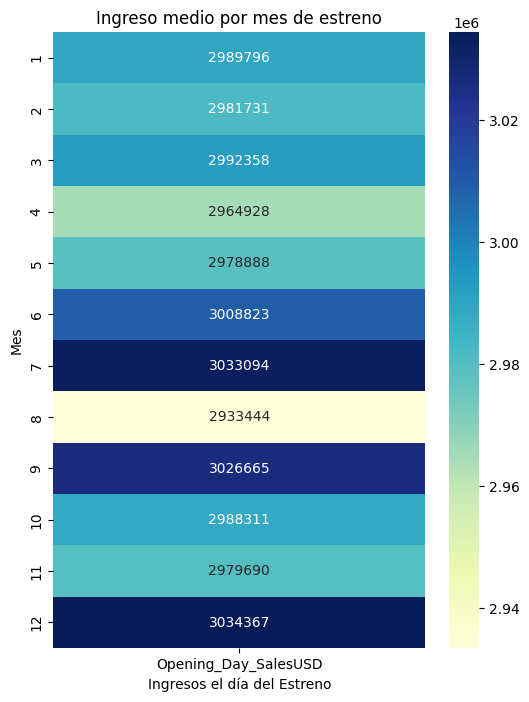

In [ ]:
# Asegurarse de que la columna sea tipo datetime
moviesCSV['ReleaseDate'] = pd.to_datetime(moviesCSV['ReleaseDate'], errors='coerce')

# Crear columna con el mes (1-12)
moviesCSV['release_month'] = moviesCSV['ReleaseDate'].dt.month

# Filtrar estrenos válidos
moviesCSV_filtered = moviesCSV[moviesCSV['Opening_Day_SalesUSD'] > 0]

# Agrupar por mes y calcular ingreso medio del estreno
monthly_revenueOD = moviesCSV_filtered.groupby('release_month')['Opening_Day_SalesUSD'].mean().reset_index()

heatmap_data = monthly_revenueOD.pivot_table(index='release_month', values='Opening_Day_SalesUSD')

plt.figure(figsize=(6,8))
sns.heatmap(heatmap_data, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Ingreso medio por mes de estreno")
plt.ylabel("Mes")
plt.xlabel("Ingresos el día del Estreno")
plt.show()


# MODELO PREDICTIVO

Para explorar la relación entre el presupuesto de una película y su recaudación global, se entrenó un modelo de regresión lineal simple.

En primer lugar, se visualizó la relación mediante un diagrama de dispersión con línea de regresión, donde se observa una clara tendencia positiva: a mayor presupuesto, mayores ingresos.

Posteriormente, el modelo fue entrenado con todos los datos del dataset y se realizaron predicciones para diferentes presupuestos de ejemplo:

A. Para una película con un presupuesto de 250 millones de dólares, el modelo estima unos 692 millones de ingresos.

B. Para una película con un presupuesto de 50 millones, la predicción es de 138
millones.

C. Para una película de bajo presupuesto de 50 mil dólares, el modelo predice unos 206 mil dólares.

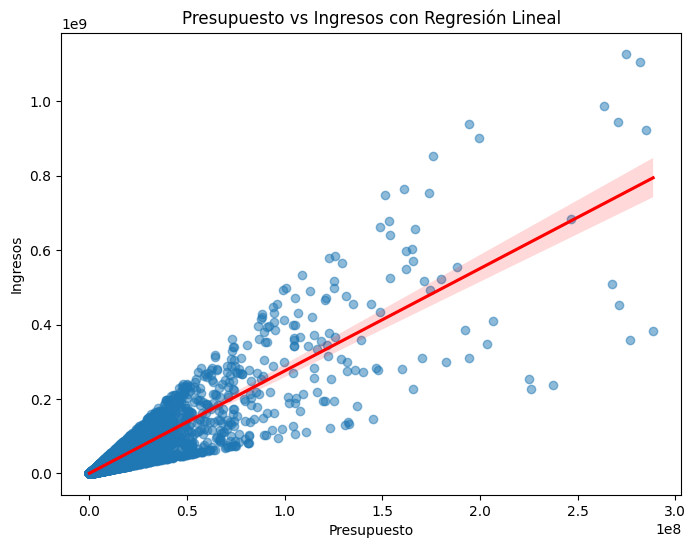

Ingreso estimado: $692,167,084
Ingreso estimado: $138,487,944
Ingreso estimado: $206,579


In [ ]:
plt.figure(figsize=(8,6))

# Scatter plot + línea de regresión
sns.regplot(x='BudgetUSD', y='Global_BoxOfficeUSD', data=movies_sample_10000, scatter_kws={'alpha':0.5}, line_kws={'color':'red'})

plt.title("Presupuesto vs Ingresos con Regresión Lineal")
plt.xlabel("Presupuesto")
plt.ylabel("Ingresos")
plt.show()


# Variables para el modelo
X = moviesCSV[['BudgetUSD']]
y = moviesCSV['Global_BoxOfficeUSD']

# Entrenar regresión lineal
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)


presupuesto_nuevo = pd.DataFrame({'BudgetUSD': [250_000_000]})
prediccion = model.predict(presupuesto_nuevo)
# presupuesto_nuevo = 50_000_000
# prediccion_real = model.predict([[presupuesto_nuevo]])
# prediccion_real = np.expm1(prediccion_log)  # exmp1 = exp(x)-1
print(f"Ingreso estimado: ${prediccion[0]:,.0f}")

presupuesto_nuevo = pd.DataFrame({'BudgetUSD': [50_000_000]})
prediccion = model.predict(presupuesto_nuevo)
print(f"Ingreso estimado: ${prediccion[0]:,.0f}")

presupuesto_nuevo = pd.DataFrame({'BudgetUSD': [50_000]})
prediccion = model.predict(presupuesto_nuevo)
print(f"Ingreso estimado: ${prediccion[0]:,.0f}")